# Sección 5 · Comparativa final: proyecto original vs proyecto corregido

En las secciones anteriores **afirmamos** que el modelo original tenía una fuga de información. Aquí lo **demostramos con un experimento**: reproducimos el modelo original tal cual y le quitamos los problemas **uno por uno**, midiendo el error en cada paso.

Al final se resume todo el proyecto y se contrasta con la viabilidad estimada al inicio.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

FIG = Path("../figuras")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 5.1 Paso 0 · Reproducir exactamente el modelo original

Se copia el código del notebook original (`original/entrega_final.ipynb`, celdas 29 y 30): Random Forest y regresión lineal que predicen `PROMEDIO DIARIO EN HORAS` a partir de `ENERGÍA ACTIVA` y `POTENCIA MÁXIMA`, con partición aleatoria 80/20.

**Primer hallazgo:** el código original **ya no corre** en scikit-learn 1.9. La lista de variables tiene `ENERGÍA ACTIVA` **dos veces** y la librería ahora lo rechaza. Para reproducirlo pasamos los valores como arreglo (`.values`), que es lo que pasaba en silencio en la versión antigua.

In [2]:
raw = pd.read_csv("../datos/raw/energia.csv")
try:
    RandomForestRegressor().fit(raw[["ENERGÍA ACTIVA", "POTENCIA MÁXIMA", "ENERGÍA ACTIVA"]], raw["PROMEDIO DIARIO EN HORAS"])
except Exception as e:
    print("El código original falla:", type(e).__name__, "→", str(e).splitlines()[0])

X = raw[["ENERGÍA ACTIVA", "POTENCIA MÁXIMA", "ENERGÍA ACTIVA"]].values
y = raw["PROMEDIO DIARIO EN HORAS"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
mae_rf_original = mean_absolute_error(y_te, RandomForestRegressor(n_estimators=100, random_state=42).fit(X_tr, y_tr).predict(X_te))
mae_lr_original = mean_absolute_error(y_te, LinearRegression().fit(X_tr, y_tr).predict(X_te))
print(f"Random Forest original:     MAE = {mae_rf_original:.2f} h   (notebook original: 0.70)")
print(f"Regresión lineal original:  MAE = {mae_lr_original:.2f} h   (notebook original: 5.93)")

El código original falla: DuplicateError → Expected unique column names, got:


Random Forest original:     MAE = 0.70 h   (notebook original: 0.70)
Regresión lineal original:  MAE = 5.92 h   (notebook original: 5.93)


Los números coinciden con el notebook original. La diferencia de 0,01 h en la regresión lineal se debe a la versión de la librería. Estamos comparando **exactamente lo mismo**.

## 5.2 Pasos 1 y 2 · Quitar los problemas uno a uno

| Paso | Cambio | Qué responde |
|---|---|---|
| 0 | Modelo original | — |
| 1 | Partición **temporal** (entrenar hasta jun-2022, evaluar jul-2022 a jun-2023) | ¿Cuánto pesaba mezclar el futuro con el pasado? |
| 2 | **Sin fuga**: predecir las horas del **mes siguiente** con información disponible (horas, energía y potencia del mes actual y del anterior) sobre datos limpios | ¿Cuánto vale el modelo como **pronóstico real**? |

En el paso 2 lo comparamos también con el **ingenuo**: "el mes que viene habrá las mismas horas de servicio que este mes".

In [3]:
# Paso 1: misma fuga, partición temporal
s1 = pd.read_csv("../datos/interim/s1_renombrado.csv", parse_dates=["fecha"])
tr = s1.fecha < "2022-07-01"
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(s1.loc[tr, ["e_activa", "pot_max"]], s1.horas_dia[tr])
mae_temporal = mean_absolute_error(s1.horas_dia[~tr], rf.predict(s1.loc[~tr, ["e_activa", "pot_max"]]))

# Paso 2: pronóstico real del mes siguiente, sin fuga, datos limpios
p = pd.read_csv("../datos/processed/energia_limpia.csv", parse_dates=["fecha"]).sort_values(["id_loc", "fecha"])
g = p.groupby("id_loc")
D = pd.DataFrame({"horas_0": p.horas_dia, "horas_1": g.horas_dia.shift(1),
                  "log_e_0": np.log1p(p.e_activa), "log_p_0": np.log1p(p.pot_max),
                  "y": g.horas_dia.shift(-1), "objetivo": p.fecha + pd.DateOffset(months=1)}).dropna(subset=["y", "horas_0"])
tr = D.objetivo < "2022-07-01"
VAR = ["horas_0", "horas_1", "log_e_0", "log_p_0"]
rf2 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0).fit(D.loc[tr, VAR], D.y[tr])
mae_sin_fuga = mean_absolute_error(D.y[~tr], rf2.predict(D.loc[~tr, VAR]))
mae_ingenuo = mean_absolute_error(D.y[~tr], D.horas_0[~tr])
mae_promedio = mean_absolute_error(D.y[~tr], np.full((~tr).sum(), D.y[tr].mean()))

escalera = pd.Series({
    "0 · Original (fuga + aleatorio)": mae_rf_original,
    "1 · Fuga + partición temporal": mae_temporal,
    "2 · Pronóstico real con RF": mae_sin_fuga,
    "2 · Pronóstico real con ingenuo": mae_ingenuo,
    "Referencia: predecir siempre el promedio": mae_promedio})
escalera.round(2).to_frame("MAE (horas/día)")

,MAE (horas/día)
0 · Original (fuga + aleatorio),0.70
1 · Fuga + partición temporal,0.83
2 · Pronóstico real con RF,0.99
2 · Pronóstico real con ingenuo,0.96
Referencia: predecir siempre el promedio,6.60


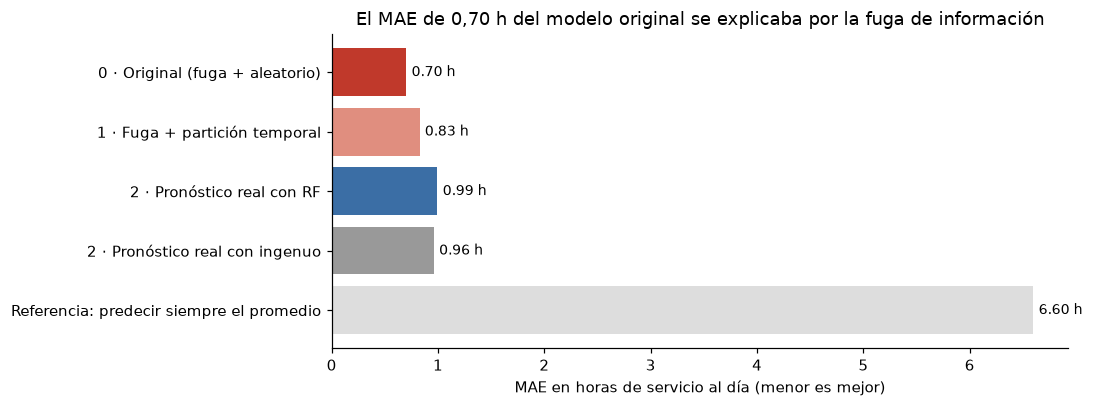

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
colores = ["#c0392b", "#e08e7f", "#3b6ea5", "#999999", "#dddddd"]
ax.barh(escalera.index, escalera.values, color=colores)
for i, v in enumerate(escalera.values): ax.text(v + 0.05, i, f"{v:.2f} h", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("MAE en horas de servicio al día (menor es mejor)")
ax.set_title("El MAE de 0,70 h del modelo original se explicaba por la fuga de información")
fig.tight_layout(); fig.savefig(FIG / "s5_escalera_fuga.png"); plt.show()

**Interpretación:**

1. **Paso 0 → 1:** con partición temporal, el error sube un poco (0,70 → ~0,83). La fuga principal **no** estaba en la partición, sino en las variables: con E y P del mismo mes, las horas se calculan casi con una fórmula (Sección 1.7).
2. **Paso 2:** cuando el modelo tiene que pronosticar **de verdad** (el mes siguiente), el Random Forest (~0,99 h) **no le gana** a la regla trivial "las mismas horas que este mes" (~0,96 h).
3. **Conclusión:** el "buen desempeño" del modelo original **no venía del modelo sino de la fuga**. Un MAE de 0,70 h parecía excelente porque se comparaba implícitamente con predecir el promedio (6,6 h de error). No se comparaba con una referencia sensata.

**Lección metodológica:** sin una referencia ingenua y sin validación temporal, es imposible saber si un modelo de series de tiempo aporta algo.

## 5.3 Resumen del proyecto: antes y después

In [5]:
m = pd.read_csv("../datos/processed/metricas_s4.csv", header=[0, 1], index_col=0)
resumen = pd.DataFrame({
    "Proyecto original": [
        "Horas de servicio (mismo mes)", "Fila suelta", "3.294 filas sin revisar", "Aleatoria 80/20",
        "Ninguna", "MAE 0,70 h (con fuga)", "No (el modelo se reconstruía con la fórmula)"],
    "Proyecto corregido": [
        "Energía activa del mes siguiente y a 3 meses",
        "133 series localidad × mes (78 modelables)",
        "47 correcciones documentadas + 475 meses faltantes explícitos",
        "Origen rodante, 12 meses de prueba",
        "Ingenuo, estacional, promedio 3 m, ETS",
        f"sMAPE {m.loc['Random Forest global', ('1 mes', 'sMAPE promedio %')]:.1f} % (1 m) · "
        f"{m.loc['Random Forest global', ('3 meses', 'sMAPE promedio %')]:.1f} % (3 m)",
        "Sí: mejora significativa a 3 meses"]},
    index=["Qué se predice", "Unidad", "Calidad de datos", "Validación", "Referencias",
           "Resultado", "¿Supera a una referencia simple?"])
resumen

,Proyecto original,Proyecto corregido
Qué se predice,Horas de servicio (mismo mes),Energía activa del mes siguiente y a 3 meses
Unidad,Fila suelta,133 series localidad × mes (78 modelables)
Calidad de datos,3.294 filas sin revisar,47 correcciones documentadas + 475 meses falta...
Validación,Aleatoria 80/20,"Origen rodante, 12 meses de prueba"
Referencias,Ninguna,"Ingenuo, estacional, promedio 3 m, ETS"
Resultado,"MAE 0,70 h (con fuga)",sMAPE 11.0 % (1 m) · 13.6 % (3 m)
¿Supera a una referencia simple?,No (el modelo se reconstruía con la fórmula),Sí: mejora significativa a 3 meses


## 5.4 Viabilidad: lo estimado al inicio vs lo logrado

Al comenzar el proyecto se estimó qué tan probable era lograr cada meta. Ahora podemos contrastarlo:

| Meta | Estimado al inicio | Resultado |
|---|---|---|
| Modelo de pronóstico mensual de energía, bien evaluado | ~90 % | ✅ **Logrado**: 6 modelos, validación temporal, 4 métricas, prueba de significancia |
| Superar al ingenuo estacional en el agregado | ~65–75 % | ✅ **Logrado**: 11,0 % vs 17,6 % (1 mes) |
| Superar también al ingenuo simple | (no estimado) | ⚠️ **Parcial**: significativo a 3 meses; no concluyente a 1 mes |
| MAPE < 10 % en todas las localidades | ~30 % | ❌ **No**: ~5–7 % en las grandes, 13–20 % en las veredas (limitadas por la oferta) |
| Encontrar un paper con los mismos datos y el mismo objetivo | ~10 % | ❌ No existe uno igual. Esto es un **aporte** del trabajo |